<a href="https://colab.research.google.com/github/agaggigit/Projek-Rekayasa-Data-JogjaPulse/blob/main/Tugas_Rekdat_Magnet_DIY.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#TUGAS REKAYASA DATA

##Anggota:
1. Akio Afifian Ahsan (24/.../TK/...)
2. Bayu Rahmat Kurnia (24/.../TK/...)
3. Dharu Bintang Mahendratama (24/.../TK/...)
4. Muhammad Affandi Argya Bagaskara (24/.../TK/...)
5. Muhammad Bintang Hidayatullah Marbun (24/.../TK/...)
6. Nabil Aufa Danaputra (24/.../TK/...)
7. Raka Bagus Samudra (24/.../TK/...)
8. Razaqi Alkautsar (24/.../TK/...)


##Topik:
Kecamatan mana yang menjadi 'magnet' di DIY, dan dari mana saja orang-orangnya datang?

##Sumber Data
JogjaPulse: An Aggregated Spatio-Temporal Mobility Dataset for Yogyakarta, Indonesia. [link dataset](https://zenodo.org/records/23157460)

##Data yang digunakan:
1. od_home_visits_kapanewon_monthly.csv
2. od_origin_homes_monthly.csv
3. presence_kapanewon_hourly.csv


In [49]:
# Setup(Library)
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import drive
from pathlib import Path
import duckdb

## 1. LOAD DATA
A. Jika ingin menaruh dataset di environment colab:
   1. Download file dataset dari [sini](https://www.google.com/url?q=https%3A%2F%2Fzenodo.org%2Frecords%2F23157460):
   2. Masukkan file ke tab Files di menu samping
   3. Jalankan sel 1A
   4. Jika session habis atau baru buka lagi, lakukan langkah 2 lagi

B. Jika ingin mengneksikan Google Drive
   1. Download file dataset dari [sini](https://www.google.com/url?q=https%3A%2F%2Fzenodo.org%2Frecords%2F23157460):
   2. Upload file tersebut ke Google Drive
   3. Jika ingin dirapihkan silahkan mmasukkan ke folder lagi di MyDrive dengan nama bebas
   4. Ubah kode 1B menyesuaikan dengan nama folder tersimpan file
   5. Jalankan sel 1B

In [50]:
# 1.A File di Environment Colab)

BASE = Path(".")
od     = pd.read_csv(BASE/"od_home_visits_kapanewon_monthly.csv")
origin = pd.read_csv(BASE/"od_origin_homes_monthly.csv")
pres   = pd.read_csv(BASE/"presence_kapanewon_hourly.csv")

In [51]:
# 1.B (File di Google Drive)

drive.mount('/content/drive')

# Sesuaikan dengan Path file nya
# BASE = Path("/content/drive/[ISI PATH FOLDER UTAMA]/")
BASE = Path("/content/drive/MyDrive/Dataset_Rekdat/")
od     = pd.read_csv(BASE/"od_home_visits_kapanewon_monthly.csv")
origin = pd.read_csv(BASE/"od_origin_homes_monthly.csv")
pres   = pd.read_csv(BASE/"presence_kapanewon_hourly.csv")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 2. Exploratory Data Analysis (EDA)

In [52]:
# 2.1 Struktur dan tipe data

for name, df in [("od", od), ("origin", origin), ("pres", pres)]:
    print(f"\n=== {name} {df.shape}")
    display(df.head())


=== od (9894, 11)


,month,origin_kab_code,origin_kab_kota,origin_code,origin_kapanewon,dest_kab_code,dest_kab_kota,dest_code,dest_kapanewon,n_maids,reduced_quality
0,2021-12,34.01,KULON PROGO,34.01.01,TEMON,34.01,KULON PROGO,34.01.01,TEMON,569,False
1,2021-12,34.01,KULON PROGO,34.01.01,TEMON,34.01,KULON PROGO,34.01.02,WATES,85,False
2,2021-12,34.01,KULON PROGO,34.01.01,TEMON,34.01,KULON PROGO,34.01.03,PANJATAN,42,False
3,2021-12,34.01,KULON PROGO,34.01.01,TEMON,34.01,KULON PROGO,34.01.04,GALUR,16,False
4,2021-12,34.01,KULON PROGO,34.01.01,TEMON,34.01,KULON PROGO,34.01.05,LENDAH,8,False



=== origin (390, 8)


,month,origin_kab_code,origin_kab_kota,origin_code,origin_kapanewon,n_homed_maids,n_homed_maids_daytime,reduced_quality
0,2021-12,34.01,KULON PROGO,34.01.01,TEMON,658,610,False
1,2021-12,34.01,KULON PROGO,34.01.02,WATES,1516,1364,False
2,2021-12,34.01,KULON PROGO,34.01.03,PANJATAN,169,149,False
3,2021-12,34.01,KULON PROGO,34.01.04,GALUR,328,311,False
4,2021-12,34.01,KULON PROGO,34.01.05,LENDAH,534,478,False



=== pres (230418, 8)


,kab_code,kab_kota,kapanewon_code,kapanewon,date,hour,n_maids,n_pings
0,34.01,KULON PROGO,34.01.01,TEMON,2021-12-01,0,16,66
1,34.01,KULON PROGO,34.01.02,WATES,2021-12-01,0,58,101
2,34.01,KULON PROGO,34.01.03,PANJATAN,2021-12-01,0,11,32
3,34.01,KULON PROGO,34.01.04,GALUR,2021-12-01,0,9,50
4,34.01,KULON PROGO,34.01.05,LENDAH,2021-12-01,0,14,74


In [53]:
# 2.2 Missing value
print("Missing di od:\n", od.isna().sum()[lambda s: s > 0])
print("\nMissing di origin:\n", origin.isna().sum()[lambda s: s > 0])

Missing di od:
 Series([], dtype: int64)

Missing di origin:
 Series([], dtype: int64)


In [54]:
# 2.3 Cek duplikasi inkonsistensi nama vs kode
print("Kapanewon asal (nama):", od.origin_kapanewon.nunique(), "| (kode):", od.origin_code.nunique())

# Nama kecamatan yang punya lebih dari satu kode
jumlah_kode_per_nama = origin.groupby("origin_kapanewon").origin_code.nunique()
nama_dobel = jumlah_kode_per_nama[jumlah_kode_per_nama > 1].index
baris_dobel = origin[origin.origin_kapanewon.isin(nama_dobel)]
hasil = baris_dobel[["origin_kab_kota", "origin_code", "origin_kapanewon"]].drop_duplicates()

display(hasil)

Kapanewon asal (nama): 77 | (kode): 78


,origin_kab_kota,origin_code,origin_kapanewon
20,BANTUL,34.02.09,JETIS
65,YOGYAKARTA,34.71.02,JETIS


In [55]:
# 2.4 Ringkasan per bulan
display(od.groupby("month").agg(
    jumlah_baris   = ("n_maids", "size"),
    total_n_maids  = ("n_maids", "sum"),
    reduced_quality= ("reduced_quality", "unique"),
))
display(origin.groupby("month").n_homed_maids.sum().rename("device_berumah"))

,jumlah_baris,total_n_maids,reduced_quality
month,,,
2021-12,2595,249141,[False]
2022-01,2624,181911,[False]
2022-02,2653,158805,[False]
2022-03,1202,29570,[True]
2022-04,820,22979,[True]


,device_berumah
month,
2021-12,122182
2022-01,86013
2022-02,77723
2022-03,23185
2022-04,14272


Statistik jumlah HP per aliran antar kapanewon (Des 2021 – Apr 2022):


,n_maids
count,9504.000000
mean,40.604798
std,98.630350
min,5.000000
25%,8.000000
50%,14.000000
75%,34.000000
max,2661.000000


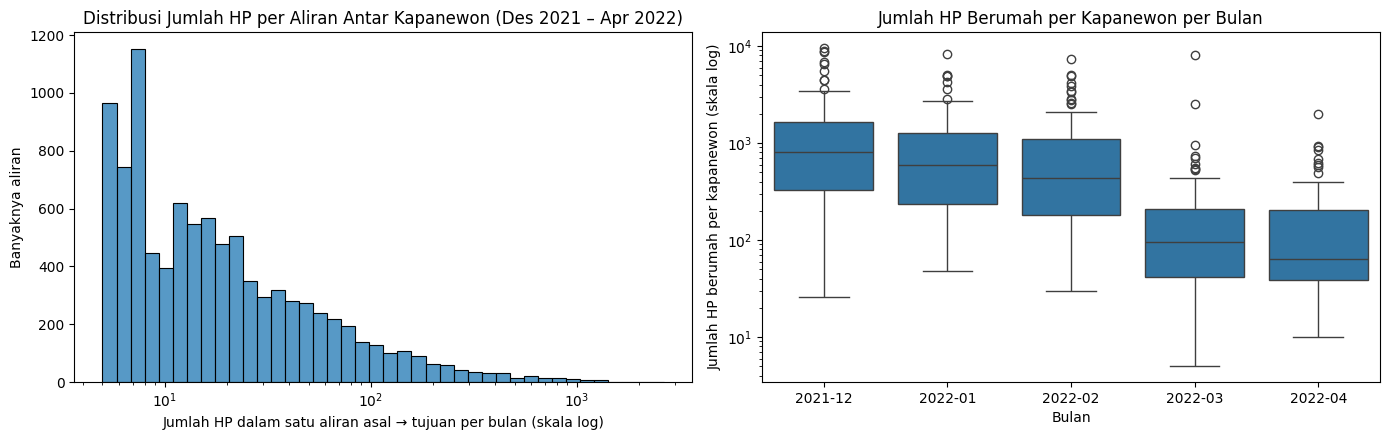

In [56]:
# 2.5 Statistik deskriptif dan distribusi

# Perpindahan ke kapanewon lain
aliran_antar_kapanewon = od[od.origin_code != od.dest_code]

print("Statistik jumlah HP per aliran antar kapanewon (Des 2021 – Apr 2022):")
display(aliran_antar_kapanewon["n_maids"].describe())

fig, (ax_kiri, ax_kanan) = plt.subplots(1, 2, figsize=(14, 4.5))

# Grafik kiri: seberapa besar aliran-alirannya
sns.histplot(data=aliran_antar_kapanewon, x="n_maids", bins=40, log_scale=True, ax=ax_kiri)
ax_kiri.set(
    title="Distribusi Jumlah HP per Aliran Antar Kapanewon (Des 2021 – Apr 2022)",
    xlabel="Jumlah HP dalam satu aliran asal → tujuan per bulan (skala log)",
    ylabel="Banyaknya aliran",
)

# Grafik kanan: apakah ukuran sampel stabil antar bulan
sns.boxplot(data=origin, x="month", y="n_homed_maids", ax=ax_kanan)
ax_kanan.set(
    title="Jumlah HP Berumah per Kapanewon per Bulan",
    xlabel="Bulan",
    ylabel="Jumlah HP berumah per kapanewon (skala log)",
    yscale="log",
)

plt.tight_layout()
plt.show()

**Temuan:**

- Grafik kiri: Sebagian besar aliran antar kapanewon berukuran kecil (puluhan HP), dan hanya sedikit aliran yang mencapai ratusan hingga ribuan HP. Pola batang yang naik-turun di ujung kiri (5–10 HP) muncul karena jumlah HP selalu bilangan bulat, sementara lebar batang pada skala log di area tersebut lebih sempit dari 1.
- Grafik kanan: Median jumlah HP berumah per kapanewon sudah menurun bertahap dari Desember hingga Februari, lalu turun tajam pada Maret–April 2022. Penurunan ini disebabkan perubahan sampel dari penyedia data, bukan perubahan mobilitas penduduk. Oleh karena itu, analisis utama hanya menggunakan data Desember 2021 – Februari 2022.

##3. Cleansing

In [57]:
# 3.1 Cek duplikat
print("Duplikat di od:", od.duplicated(["month", "origin_code", "dest_code"]).sum())
print("Duplikat di origin:", origin.duplicated(["month", "origin_code"]).sum())

Duplikat di od: 0
Duplikat di origin: 0


In [58]:
# 3.2 Buang data Maret–April (kualitas rendah)
od_bersih = od[~od["reduced_quality"]]
origin_bersih = origin[~origin["reduced_quality"]]
print("od     - awal:", len(od), "| setelah buang Mar–Apr:", len(od_bersih))
print("origin - awal:", len(origin), "| setelah buang Mar–Apr:", len(origin_bersih))

od     - awal: 9894 | setelah buang Mar–Apr: 7872
origin - awal: 390 | setelah buang Mar–Apr: 234


In [59]:
# 3.3 Buang aliran ke kapanewon sendiri
od_bersih = od_bersih[od_bersih["origin_code"] != od_bersih["dest_code"]]
print("Setelah membuang aliran ke kapanewon sendiri:", len(od_bersih))

Setelah membuang aliran ke kapanewon sendiri: 7638


In [60]:
# 3.4 Cek jumlah HP berumah yang kosong (disensor karena < 5 HP)
print("Jumlah HP berumah yang kosong:", origin_bersih["n_homed_maids_daytime"].isna().sum())

Jumlah HP berumah yang kosong: 0


In [61]:
# 3.5 Dampak sensor privasi (dari ringkasan resmi dataset)
display(pd.read_csv(BASE/"od_summary.csv"))

,k,min_nights,od_rows_total,od_rows_published,od_rows_suppressed_pct,inter_zonal_flow_kept_pct,origin_rows_published
0,5,2,19263,9894,48.6,95.3,390


In [62]:
# 3.6 Tandai outlier: kapanewon dengan HP tercatat jauh melebihi penduduknya
pop = pd.read_csv(BASE / "home_maids_vs_population_kapanewon.csv")
display(pop.sort_values("ratio", ascending=False).head(5))

,KAB_KOTA,KEC_KAPN,n_users,pop_actual,ratio
0,YOGYAKARTA,GONDOMANAN,28874,12850.0,2.247004
1,SLEMAN,PAKEM,20241,37580.0,0.538611
2,SLEMAN,DEPOK,39609,130980.0,0.302405
3,SLEMAN,SEYEGAN,15469,51860.0,0.298284
4,YOGYAKARTA,JETIS,6922,23480.0,0.294804


**Ringkasan Data Cleaning:**
- Tidak ditemukan duplikat pada kedua file.
- Data Maret–April 2022 dibuang karena kualitasnya rendah.
- Aliran ke kapanewon sendiri dibuang karena bukan perpindahan.
- Tidak ada penyebut yang kosong pada periode Des 2021 – Feb 2022.
- Sensor privasi (k = 5) menghapus 48,6% pasangan asal–tujuan, tetapi 95,3% total aliran antar kapanewon tetap tersimpan, sehingga data yang hilang sebagian besar adalah aliran kecil (kurang dari 5 HP).
- Gondomanan ditandai sebagai outlier (HP tercatat 2,2× jumlah penduduk) namun tetap dipertahankan.

#4. Data Integration

In [63]:
# 4.1 Samakan skema file penduduk dan beri kode kapanewon
penduduk = pd.read_csv(BASE / "home_maids_vs_population_kapanewon.csv").rename(columns={
    "KAB_KOTA": "kab_kota", "KEC_KAPN": "kapanewon", "pop_actual": "penduduk"})

kamus_kode = (origin_bersih[["origin_kab_kota", "origin_kapanewon", "origin_code"]]
              .drop_duplicates()
              .rename(columns={"origin_kab_kota": "kab_kota",
                               "origin_kapanewon": "kapanewon",
                               "origin_code": "kode"}))

penduduk = penduduk.merge(kamus_kode, on=["kab_kota", "kapanewon"], how="left")
print("Kapanewon tanpa kode:", penduduk["kode"].isna().sum())   # harus 0

Kapanewon tanpa kode: 0


4.2 Menggabungkan data aliran dengan jumlah HP berumah

Jumlah aliran mentah tidak bisa langsung dibandingkan antar kapanewon, karena kapanewon dengan banyak penduduk wajar memiliki aliran yang besar. Karena itu, setiap aliran perlu dibandingkan dengan jumlah HP yang berumah di kapanewon asalnya. Kedua angka ini berada di file yang berbeda, sehingga perlu digabungkan terlebih dahulu.

In [64]:
# 4.2 Tambahkan jumlah HP berumah di kapanewon asal ke setiap baris aliran
hp_berumah_asal = origin_bersih[["month", "origin_code",
                                 "n_homed_maids", "n_homed_maids_daytime"]]

data = od_bersih.merge(hp_berumah_asal, on=["month", "origin_code"], how="left",
                       validate="many_to_one")
print("Baris sebelum:", len(od_bersih), "| sesudah:", len(data),
      "| jumlah HP berumah yang kosong:", data["n_homed_maids_daytime"].isna().sum())

Baris sebelum: 7638 | sesudah: 7638 | jumlah HP berumah yang kosong: 0


In [65]:
# 4.3 Tambahkan jumlah penduduk kapanewon asal
pend = penduduk[["kode", "penduduk"]]
pend_asal = pend.rename(columns={"kode": "origin_code", "penduduk": "penduduk_asal"})
data = data.merge(pend_asal, on="origin_code", how="left")

print("Penduduk asal kosong  :", data["penduduk_asal"].isna().sum())

Penduduk asal kosong  : 0


In [66]:
# 4.4 Apakah jumlah HP berumah sejalan dengan jumlah penduduk?
hp_per_kapanewon = origin_bersih.groupby("origin_code")["n_homed_maids"].mean().reset_index()
pend_asal = pend.rename(columns={"kode": "origin_code"})
cek = hp_per_kapanewon.merge(pend_asal, on="origin_code", how="left")

# hitung korelasi, dengan dan tanpa Gondomanan (outlier)
korelasi_semua = cek["n_homed_maids"].corr(cek["penduduk"])

tanpa_gondomanan = cek[cek["origin_code"] != "34.71.10"]
korelasi_tanpa_gondomanan = tanpa_gondomanan["n_homed_maids"].corr(tanpa_gondomanan["penduduk"])

print("Korelasi Pearson (semua kapanewon)     :", round(korelasi_semua, 2))
print("Korelasi Pearson (tanpa Gondomanan)    :", round(korelasi_tanpa_gondomanan, 2))

Korelasi Pearson (semua kapanewon)     : 0.83
Korelasi Pearson (tanpa Gondomanan)    : 0.85


##5. Transformation

In [67]:
# 5.1 Proporsi HP dari kapanewon asal yang terlihat di kapanewon tujuan
data["rate"] = data["n_maids"] / data["n_homed_maids_daytime"]
display(data["rate"].describe())

,rate
count,7638.000000
mean,0.043794
std,0.063449
min,0.000593
25%,0.008677
50%,0.020678
75%,0.050314
max,0.705196


In [68]:
# 5.2 Jumlah HP dari kapanewon lain yang terlihat di setiap kapanewon tujuan, per bulan
pengunjung = data.groupby(["month", "dest_code", "dest_kapanewon", "dest_kab_kota"], as_index=False)["n_maids"].sum()
pengunjung = pengunjung.rename(columns={"n_maids": "pengunjung_luar"})

display(pengunjung.head())
print("Jumlah baris:", len(pengunjung))

,month,dest_code,dest_kapanewon,dest_kab_kota,pengunjung_luar
0,2021-12,34.01.01,TEMON,KULON PROGO,728
1,2021-12,34.01.02,WATES,KULON PROGO,2469
2,2021-12,34.01.03,PANJATAN,KULON PROGO,239
3,2021-12,34.01.04,GALUR,KULON PROGO,252
4,2021-12,34.01.05,LENDAH,KULON PROGO,374


Jumlah baris: 234


In [69]:
# 5.3 Tambahkan jumlah HP berumah di kapanewon tujuan
hp_berumah_tujuan = origin_bersih[["month", "origin_code", "n_homed_maids"]].rename(
    columns={"origin_code": "dest_code", "n_homed_maids": "hp_berumah_tujuan"})

pengunjung = pengunjung.merge(hp_berumah_tujuan, on=["month", "dest_code"],
                              how="left", validate="one_to_one")

# Indeks magnet: berapa pengunjung dari luar untuk setiap 1 HP berumah di kapanewon itu
pengunjung["indeks_magnet"] = pengunjung["pengunjung_luar"] / pengunjung["hp_berumah_tujuan"]

In [70]:
# 5.4 Rata-rata Des 2021 – Feb 2022
magnet = (pengunjung
          .groupby(["dest_code", "dest_kapanewon", "dest_kab_kota"], as_index=False)
          .agg(pengunjung_luar=("pengunjung_luar", "mean"),
               indeks_magnet=("indeks_magnet", "mean")))
display(magnet["indeks_magnet"].describe())

,indeks_magnet
count,78.000000
mean,1.817034
std,2.215239
min,0.288612
25%,0.879127
50%,1.111304
75%,1.510378
max,12.209156


In [71]:
# 5.5 Diskretisasi: magnet jika pengunjung dari luar lebih banyak dari HP berumahnya
magnet["kelas_magnet"] = np.where(magnet["indeks_magnet"] >= 1,
                                  "Magnet (hijau)", "Pengirim (merah)")
display(magnet["kelas_magnet"].value_counts())

,count
kelas_magnet,
Magnet (hijau),48
Pengirim (merah),30


##6. Data Warehouse
Warehouse ini menyimpan data hasil integrasi dalam bentuk star schema sehingga analisis lintas level (kapanewon–kabupaten) dan lintas waktu dapat dilakukan dengan query OLAP.

```
#6.1 Desain Star-Schema
                  ┌──────────────────┐
                  │    dim_bulan     │
                  │ bulan (PK)       │
                  │ nama_bulan       │
                  │ libur_nataru     │
                  └────────┬─────────┘
                           │
┌──────────────────┐  ┌────┴──────────────┐  ┌──────────────────┐
│  dim_kapanewon   │  │  fact_kunjungan   │  │  dim_kapanewon   │
│  (peran: asal)   ├──┤ bulan (FK)        ├──┤ (peran: tujuan)  │
│ kode_kapanewon   │  │ kode_asal (FK)    │  │ kode_kapanewon   │
│ nama_kapanewon   │  │ kode_tujuan (FK)  │  │ ...              │
│ kode_kab         │  │ jumlah_hp         │  └──────────────────┘
│ nama_kab         │  └───────────────────┘
│ penduduk         │  ┌───────────────────┐
└──────────────────┘  │  fact_hp_berumah  │
                      │ bulan (FK)        │
                      │ kode_kapanewon(FK)│
                      │ hp_berumah        │
                      │ hp_berumah_siang  │
                      └───────────────────┘
```

In [72]:
# 6.2 Susun tabel dimensi dan fakta dari data hasil cleaning dan integrasi

# Dimensi kapanewon
dim_kapanewon = origin_bersih[["origin_code", "origin_kapanewon", "origin_kab_code", "origin_kab_kota"]]
dim_kapanewon = dim_kapanewon.drop_duplicates()
dim_kapanewon = dim_kapanewon.rename(columns={
    "origin_code": "kode_kapanewon", "origin_kapanewon": "nama_kapanewon",
    "origin_kab_code": "kode_kab", "origin_kab_kota": "nama_kab"})

penduduk_per_kode = penduduk[["kode", "penduduk"]].rename(columns={"kode": "kode_kapanewon"})
dim_kapanewon = dim_kapanewon.merge(penduduk_per_kode, on="kode_kapanewon",
                                    how="left", validate="one_to_one")

# Dimensi bulan
dim_bulan = pd.DataFrame({
    "bulan":        ["2021-12", "2022-01", "2022-02"],
    "nama_bulan":   ["Desember 2021", "Januari 2022", "Februari 2022"],
    "libur_nataru": [True, False, False],
})

# Fakta kunjungan
fact_kunjungan = od_bersih[["month", "origin_code", "dest_code", "n_maids"]].rename(columns={
    "month": "bulan", "origin_code": "kode_asal",
    "dest_code": "kode_tujuan", "n_maids": "jumlah_hp"})

# Fakta HP berumah
fact_hp_berumah = origin_bersih[["month", "origin_code", "n_homed_maids", "n_homed_maids_daytime"]].rename(columns={
    "month": "bulan", "origin_code": "kode_kapanewon",
    "n_homed_maids": "hp_berumah", "n_homed_maids_daytime": "hp_berumah_siang"})

print("dim_kapanewon:", len(dim_kapanewon), "| dim_bulan:", len(dim_bulan),
      "| fact_kunjungan:", len(fact_kunjungan), "| fact_hp_berumah:", len(fact_hp_berumah))

dim_kapanewon: 78 | dim_bulan: 3 | fact_kunjungan: 7638 | fact_hp_berumah: 234


In [73]:
# 6.3 Muat tabel ke database DuckDB (satu file, tanpa server)
con = duckdb.connect("jogjapulse_dw.duckdb")
tabel = {"dim_kapanewon": dim_kapanewon, "dim_bulan": dim_bulan,
         "fact_kunjungan": fact_kunjungan, "fact_hp_berumah": fact_hp_berumah}

for nama_tabel, df in tabel.items():
    con.execute(f"CREATE OR REPLACE TABLE {nama_tabel} AS SELECT * FROM df")

display(con.sql("SHOW TABLES").df())

,name
0,dim_bulan
1,dim_kapanewon
2,fact_hp_berumah
3,fact_kunjungan


In [74]:
query_rollup = """
SELECT a.nama_kab AS kab_asal,
       t.nama_kab AS kab_tujuan,
       SUM(f.jumlah_hp) / 3 AS rata2_per_bulan
FROM fact_kunjungan f
JOIN dim_kapanewon a ON f.kode_asal   = a.kode_kapanewon
JOIN dim_kapanewon t ON f.kode_tujuan = t.kode_kapanewon
WHERE a.nama_kab <> t.nama_kab
GROUP BY kab_asal, kab_tujuan
ORDER BY rata2_per_bulan DESC
"""
display(con.sql(query_rollup).df().head(8))

,kab_asal,kab_tujuan,rata2_per_bulan
0,SLEMAN,YOGYAKARTA,11334.666667
1,SLEMAN,BANTUL,9102.000000
2,BANTUL,SLEMAN,8959.666667
3,BANTUL,YOGYAKARTA,8234.666667
4,YOGYAKARTA,SLEMAN,5299.666667
5,YOGYAKARTA,BANTUL,3477.000000
6,SLEMAN,KULON PROGO,2335.333333
7,KULON PROGO,SLEMAN,2251.000000


Catatan: menjumlahkan antar kecamatan tujuan bisa menghitung satu HP lebih dari sekali. HP warga Sleman yang mengunjungi Gondokusuman dan Umbulharjo di bulan yang sama terhitung dua kali di “Sleman → Kota Yogya”. Jadi angka roll-up ini artinya jumlah kunjungan HP ke kapanewon, bukan jumlah HP unik.

In [75]:
query_drilldown = """
SELECT t.nama_kapanewon, SUM(f.jumlah_hp) / 3 AS rata2_pengunjung_luar
FROM fact_kunjungan f
JOIN dim_kapanewon t ON f.kode_tujuan = t.kode_kapanewon
WHERE t.nama_kab = 'YOGYAKARTA'
GROUP BY t.nama_kapanewon
ORDER BY rata2_pengunjung_luar DESC
"""
display(con.sql(query_drilldown).df().head())

,nama_kapanewon,rata2_pengunjung_luar
0,UMBULHARJO,4935.666667
1,GONDOKUSUMAN,4933.666667
2,GONDOMANAN,2684.666667
3,JETIS,2659.000000
4,KOTAGEDE,2253.000000


In [76]:
query_slice = """
SELECT b.nama_bulan, t.nama_kapanewon, SUM(f.jumlah_hp) AS pengunjung_luar
FROM fact_kunjungan f
JOIN dim_kapanewon t ON f.kode_tujuan = t.kode_kapanewon
JOIN dim_bulan b     ON f.bulan       = b.bulan
WHERE b.libur_nataru
GROUP BY b.nama_bulan, t.nama_kapanewon
ORDER BY pengunjung_luar DESC
"""
display(con.sql(query_slice).df().head())

,nama_bulan,nama_kapanewon,pengunjung_luar
0,Desember 2021,DEPOK,10628.0
1,Desember 2021,NGAGLIK,8218.0
2,Desember 2021,GAMPING,8167.0
3,Desember 2021,BANGUNTAPAN,7829.0
4,Desember 2021,PAKEM,7381.0


In [77]:
query_dice = """
SELECT a.nama_kapanewon AS asal, t.nama_kapanewon AS tujuan,
       SUM(f.jumlah_hp) / 2 AS rata2_per_bulan
FROM fact_kunjungan f
JOIN dim_kapanewon a ON f.kode_asal   = a.kode_kapanewon
JOIN dim_kapanewon t ON f.kode_tujuan = t.kode_kapanewon
WHERE a.nama_kab = 'BANTUL'
  AND t.nama_kab = 'YOGYAKARTA'
  AND f.bulan IN ('2022-01', '2022-02')
GROUP BY asal, tujuan
ORDER BY rata2_per_bulan DESC
"""
display(con.sql(query_dice).df().head())

,asal,tujuan,rata2_per_bulan
0,BANGUNTAPAN,UMBULHARJO,942.0
1,BANGUNTAPAN,KOTAGEDE,534.0
2,BANGUNTAPAN,GONDOKUSUMAN,400.0
3,KASIHAN,WIROBRAJAN,262.5
4,SEWON,UMBULHARJO,255.0


In [78]:
query_rate = """
SELECT a.nama_kapanewon AS asal, t.nama_kapanewon AS tujuan,
       ROUND(AVG(f.jumlah_hp * 1.0 / h.hp_berumah_siang), 3) AS rata2_rate
FROM fact_kunjungan f
JOIN fact_hp_berumah h ON f.bulan = h.bulan AND f.kode_asal = h.kode_kapanewon
JOIN dim_kapanewon a   ON f.kode_asal   = a.kode_kapanewon
JOIN dim_kapanewon t   ON f.kode_tujuan = t.kode_kapanewon
WHERE a.nama_kapanewon = 'NGAGLIK'
GROUP BY asal, tujuan
ORDER BY rata2_rate DESC
"""
display(con.sql(query_rate).df().head())

,asal,tujuan,rata2_rate
0,NGAGLIK,DEPOK,0.213
1,NGAGLIK,NGEMPLAK,0.187
2,NGAGLIK,PAKEM,0.161
3,NGAGLIK,MLATI,0.113
4,NGAGLIK,GONDOKUSUMAN,0.051


##7. Analisis dan Visualisasi

In [79]:
# Jumlah bulan dalam periode analisis (Des 2021 – Feb 2022), dipakai untuk menghitung rata-rata per bulan
JUMLAH_BULAN = 3

In [80]:
# 7.1 Menyiapkan peta kapanewon dan menggabungkannya dengan indeks magnet
import geopandas as gpd
from shapely import wkt
from matplotlib.colors import TwoSlopeNorm

URL_PETA = "https://raw.githubusercontent.com/badaksambel/jogjapulse/main/release/data/kapanewon_wkt.csv"
peta_mentah = pd.read_csv(URL_PETA, dtype={"KEC_CODE": str})
peta = gpd.GeoDataFrame(peta_mentah, geometry=peta_mentah["wkt"].apply(wkt.loads), crs="EPSG:4326")
peta = peta.merge(magnet, left_on="KEC_CODE", right_on="dest_code", how="left", validate="one_to_one")
print("Kapanewon di peta tanpa data magnet:", peta["indeks_magnet"].isna().sum())

titik_label = peta.representative_point()
koordinat = dict(zip(peta["KEC_CODE"], zip(titik_label.x, titik_label.y)))

Kapanewon di peta tanpa data magnet: 0


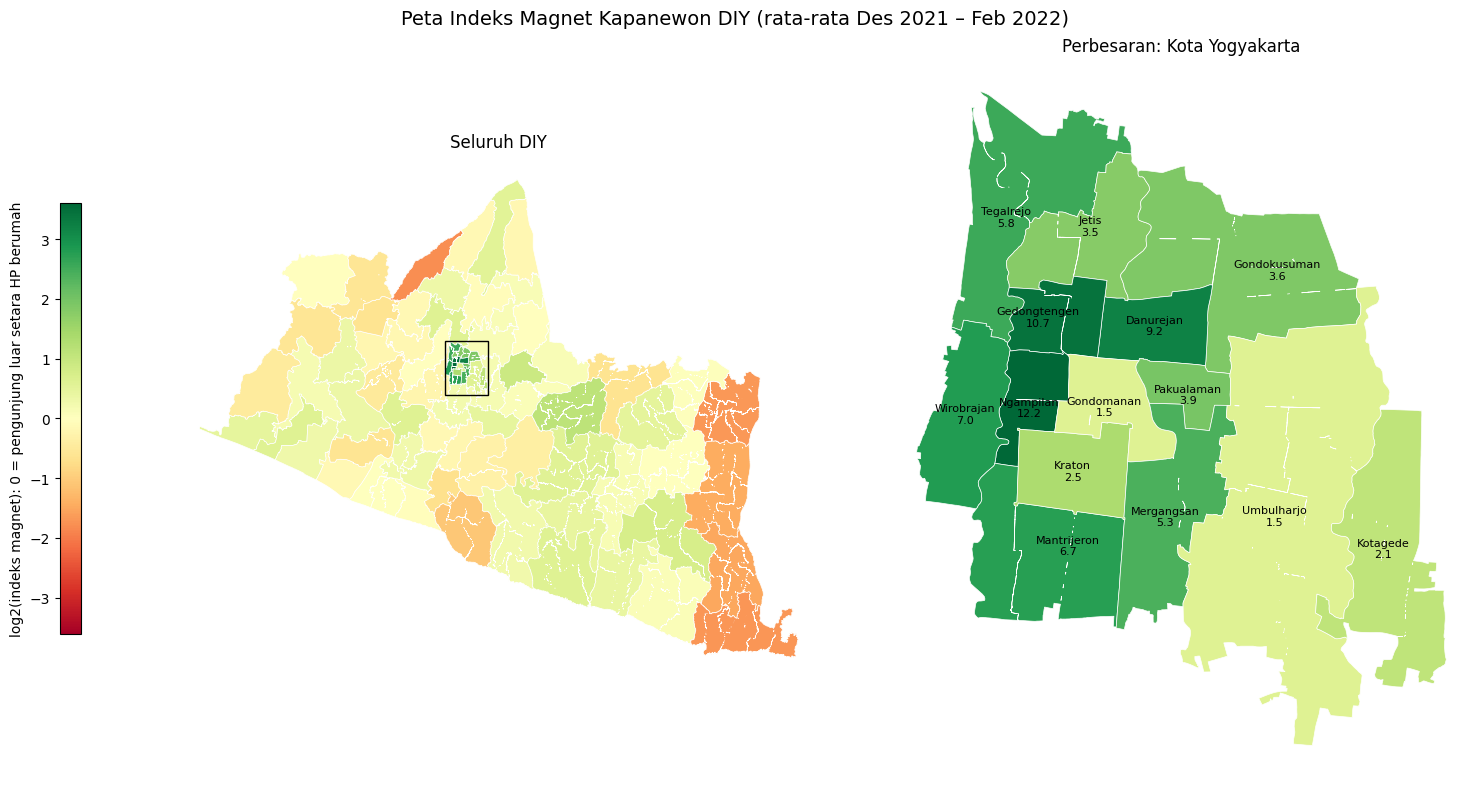

In [81]:
# 7.2 Peta indeks magnet seluruh DIY dan perbesaran Kota Yogyakarta
peta["log2_indeks"] = np.log2(peta["indeks_magnet"])
batas = peta["log2_indeks"].abs().max()
skala_warna = TwoSlopeNorm(vcenter=0, vmin=-batas, vmax=batas)
gaya = dict(column="log2_indeks", cmap="RdYlGn", norm=skala_warna, edgecolor="white", linewidth=0.5)

fig, (ax_diy, ax_kota) = plt.subplots(1, 2, figsize=(16, 8), gridspec_kw={"width_ratios": [1.3, 1]})

# Panel kiri: seluruh DIY
peta.plot(ax=ax_diy, legend=True,
          legend_kwds={"label": "log2(indeks magnet): 0 = pengunjung luar setara HP berumah",
                       "shrink": 0.6, "location": "left"}, **gaya)
ax_diy.set_title("Seluruh DIY")

# Panel kanan: perbesaran Kota Yogyakarta, dengan nama dan nilai indeks
kota = peta[peta["KAB_KOTA"] == "YOGYAKARTA"]
kota.plot(ax=ax_kota, **gaya)
for kode in kota["KEC_CODE"]:
    x, y = koordinat[kode]
    baris = peta.loc[peta["KEC_CODE"] == kode].iloc[0]
    ax_kota.annotate(f"{baris['KEC_KAPN'].title()}\n{baris['indeks_magnet']:.1f}", (x, y),
                     fontsize=8, ha="center", va="center")
ax_kota.set_title("Perbesaran: Kota Yogyakarta")

# Kotak penanda area Kota Yogyakarta di panel kiri
xmin, ymin, xmax, ymax = kota.total_bounds
ax_diy.add_patch(plt.Rectangle((xmin, ymin), xmax - xmin, ymax - ymin,
                               fill=False, edgecolor="black", linewidth=1))

for ax in (ax_diy, ax_kota):
    ax.set_axis_off()
fig.suptitle("Peta Indeks Magnet Kapanewon DIY (rata-rata Des 2021 – Feb 2022)", fontsize=14)
plt.tight_layout()
plt.show()

Hampir seluruh Kota Yogyakarta berwarna hijau, dengan indeks tertinggi di Ngampilan (12,2), Gedongtengen (10,7), dan Danurejan (9,2). Kapanewon di timur Gunungkidul paling merah. Secara keseluruhan 48 kapanewon tergolong magnet dan 30 pengirim.

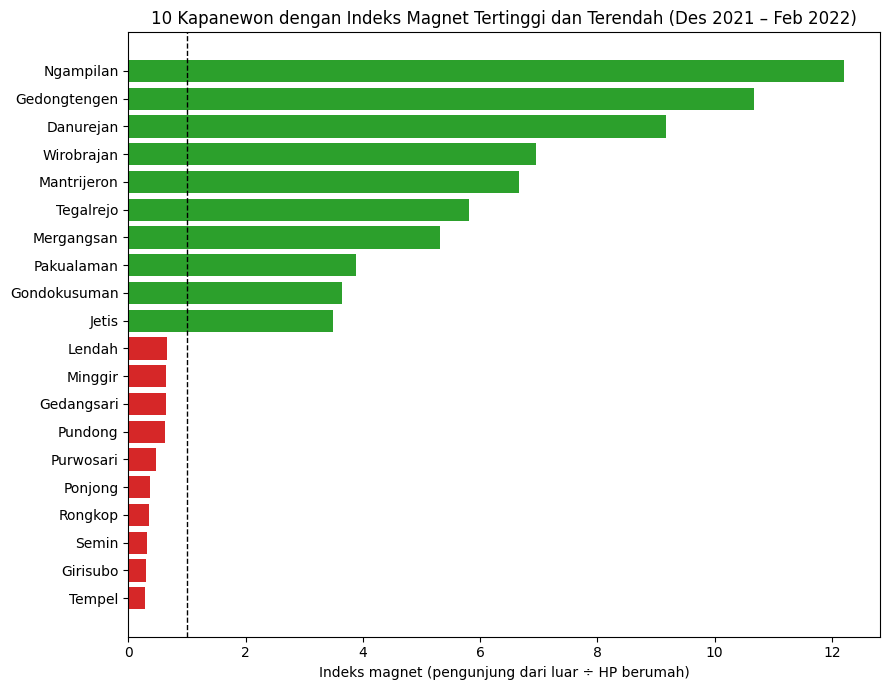

In [82]:
# 7.3 Sepuluh kapanewon dengan indeks magnet tertinggi dan terendah
urut = magnet.sort_values("indeks_magnet", ascending=False)
top_bottom = pd.concat([urut.head(10), urut.tail(10)])
warna = np.where(top_bottom["indeks_magnet"] >= 1, "tab:green", "tab:red")

fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(top_bottom["dest_kapanewon"].str.title(), top_bottom["indeks_magnet"], color=warna)
ax.axvline(1, color="black", linestyle="--", linewidth=1)
ax.invert_yaxis()
ax.set(title="10 Kapanewon dengan Indeks Magnet Tertinggi dan Terendah (Des 2021 – Feb 2022)",
       xlabel="Indeks magnet (pengunjung dari luar ÷ HP berumah)", ylabel="")
plt.tight_layout()
plt.show()

Lima magnet relatif teratas seluruhnya berada di Kota Yogyakarta. Indeks terendah ada di Tempel (0,29), Girisubo, Semin, Rongkop, dan Ponjong.

,dest_kapanewon,dest_kab_kota,pengunjung_hp,peringkat_hp,perkiraan_orang,peringkat_perkiraan
53,DEPOK,SLEMAN,9176.0,1,363622.0,1
23,BANGUNTAPAN,BANTUL,6102.0,2,260839.0,2
27,KASIHAN,BANTUL,4646.0,8,216577.0,3
47,GAMPING,SLEMAN,5479.0,4,208049.0,4
58,NGAGLIK,SLEMAN,5938.0,3,203744.0,5
76,UMBULHARJO,YOGYAKARTA,4936.0,5,194356.0,6
66,GONDOKUSUMAN,YOGYAKARTA,4934.0,6,185451.0,7
52,MLATI,SLEMAN,4902.0,7,166491.0,8
29,WONOSARI,GUNUNGKIDUL,1891.0,22,166488.0,9
73,GONDOMANAN,YOGYAKARTA,2685.0,14,131239.0,10


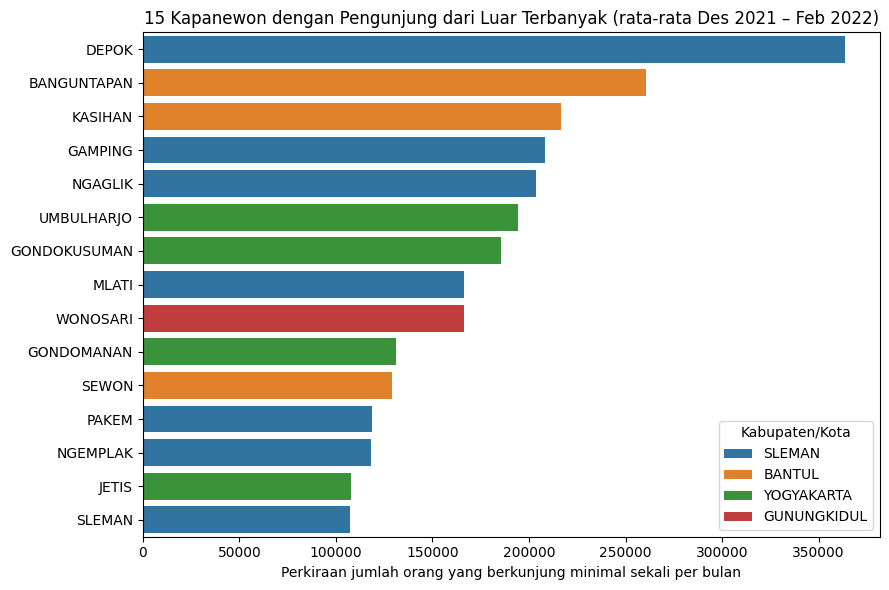

In [83]:
# 7.4 Perkiraan jumlah pengunjung dari luar per kapanewon (magnet absolut)
data["perkiraan_orang"] = data["rate"] * data["penduduk_asal"]

magnet_absolut = (data.groupby(["dest_code", "dest_kapanewon", "dest_kab_kota"], as_index=False)
                  .agg(pengunjung_hp=("n_maids", "sum"),
                       perkiraan_orang=("perkiraan_orang", "sum")))
magnet_absolut[["pengunjung_hp", "perkiraan_orang"]] /= JUMLAH_BULAN   # rata-rata per bulan

magnet_absolut["peringkat_hp"] = magnet_absolut["pengunjung_hp"].rank(ascending=False).astype(int)
magnet_absolut["peringkat_perkiraan"] = magnet_absolut["perkiraan_orang"].rank(ascending=False).astype(int)
magnet_absolut = magnet_absolut.sort_values("perkiraan_orang", ascending=False)

kolom_tampil = ["dest_kapanewon", "dest_kab_kota", "pengunjung_hp", "peringkat_hp",
                "perkiraan_orang", "peringkat_perkiraan"]
display(magnet_absolut[kolom_tampil].head(10).round(0))

top15 = magnet_absolut.head(15)
fig, ax = plt.subplots(figsize=(9, 6))
sns.barplot(data=top15, y="dest_kapanewon", x="perkiraan_orang", hue="dest_kab_kota", dodge=False, ax=ax)
ax.set(title="15 Kapanewon dengan Pengunjung dari Luar Terbanyak (rata-rata Des 2021 – Feb 2022)",
       xlabel="Perkiraan jumlah orang yang berkunjung minimal sekali per bulan", ylabel="")
ax.legend(title="Kabupaten/Kota")
plt.tight_layout()
plt.show()

Depok menjadi magnet terbesar (±364 ribu orang/bulan), disusul Banguntapan, Kasihan, Gamping, dan Ngaglik. Magnet absolut didominasi kapanewon penyangga kota di Sleman dan Bantul, bukan pusat kota.

In [84]:
# 7.5 Uji ketahanan: apakah peringkat berubah jika kapanewon asal dengan sampel kecil dibuang?
hasil = magnet_absolut[["dest_code", "dest_kapanewon", "peringkat_perkiraan"]].copy()

for batas_min in [50, 100, 200]:
    sampel_cukup = data[data["n_homed_maids_daytime"] >= batas_min]
    perkiraan = sampel_cukup.groupby("dest_code")["perkiraan_orang"].sum() / JUMLAH_BULAN
    peringkat = perkiraan.rank(ascending=False)
    hasil[f"peringkat_min{batas_min}"] = hasil["dest_code"].map(peringkat).astype("Int64")

display(hasil.head(12))

,dest_code,dest_kapanewon,peringkat_perkiraan,peringkat_min50,peringkat_min100,peringkat_min200
53,34.04.07,DEPOK,1,1,1,1
23,34.02.12,BANGUNTAPAN,2,2,2,2
27,34.02.16,KASIHAN,3,3,3,5
47,34.04.01,GAMPING,4,4,4,3
58,34.04.12,NGAGLIK,5,5,5,4
76,34.71.13,UMBULHARJO,6,6,6,6
66,34.71.03,GONDOKUSUMAN,7,7,7,7
52,34.04.06,MLATI,8,8,8,8
29,34.03.01,WONOSARI,9,9,11,15
73,34.71.10,GONDOMANAN,10,10,10,12


Delapan peringkat teratas hampir tidak berubah. Wonosari turun dari peringkat 9 ke 15 saat asal dengan sampel kecil dibuang, sehingga posisinya sensitif terhadap pembesaran.

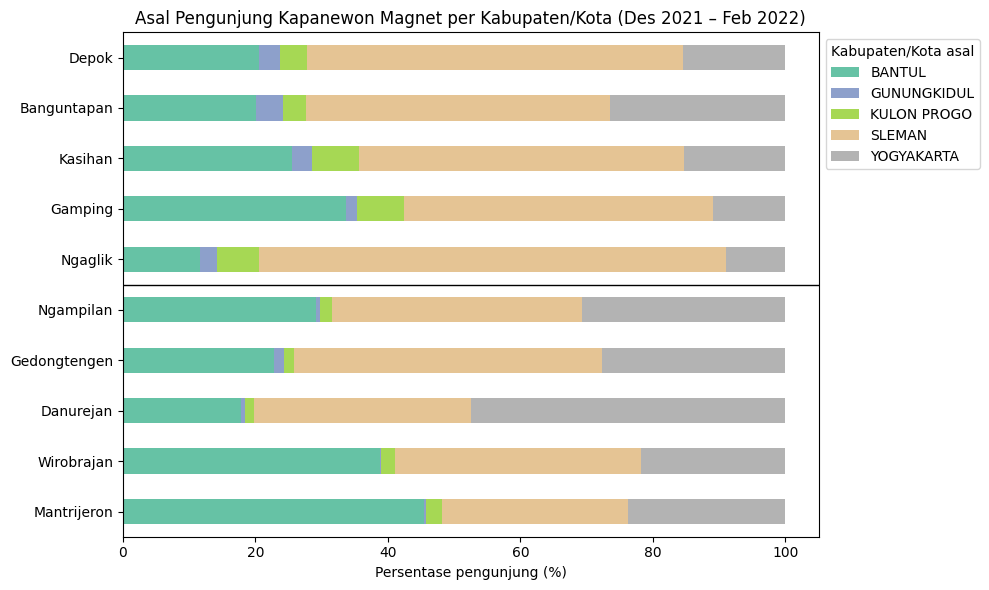

In [85]:
# 7.6 Komposisi asal pengunjung per kabupaten/kota untuk kapanewon magnet
TOP_ABSOLUT = magnet_absolut.head(5)["dest_code"].tolist()
TOP_RELATIF = magnet.nlargest(5, "indeks_magnet")["dest_code"].tolist()
pilihan = TOP_ABSOLUT + TOP_RELATIF

komposisi = (data[data["dest_code"].isin(pilihan)]
             .groupby(["dest_code", "origin_kab_kota"])["n_maids"].sum()
             .unstack(fill_value=0))
komposisi = komposisi.div(komposisi.sum(axis=1), axis=0) * 100   # ubah ke persen per baris
komposisi = komposisi.loc[pilihan]                                # urutkan sesuai daftar pilihan

nama_tujuan = magnet.set_index("dest_code")["dest_kapanewon"].str.title()
komposisi.index = [nama_tujuan[k] for k in komposisi.index]

ax = komposisi.plot(kind="barh", stacked=True, figsize=(10, 6), colormap="Set2")
ax.invert_yaxis()
ax.axhline(4.5, color="black", linewidth=1)   # pemisah magnet absolut dan relatif
ax.set(title="Asal Pengunjung Kapanewon Magnet per Kabupaten/Kota (Des 2021 – Feb 2022)",
       xlabel="Persentase pengunjung (%)", ylabel="")
ax.legend(title="Kabupaten/Kota asal", bbox_to_anchor=(1, 1))
plt.tight_layout()
plt.show()

Magnet absolut didominasi pengunjung dari Sleman. Magnet relatif di sisi barat daya kota (Wirobrajan, Mantrijeron) banyak menarik pengunjung dari Bantul, sedangkan Danurejan lebih banyak dikunjungi warga Kota Yogyakarta sendiri.

In [86]:
# 7.7 Lima kapanewon asal terbesar untuk setiap kapanewon magnet
top_asal = (data[data["dest_code"].isin(pilihan)]
            .groupby(["dest_code", "dest_kapanewon", "origin_kapanewon", "origin_kab_kota"],
                     as_index=False)["n_maids"].sum())
top_asal["rata2_hp_per_bulan"] = (top_asal["n_maids"] / JUMLAH_BULAN).round(0)

top_asal = (top_asal
            .sort_values(["dest_kapanewon", "rata2_hp_per_bulan"], ascending=[True, False])
            .groupby("dest_kapanewon").head(5))
display(top_asal[["dest_kapanewon", "origin_kapanewon", "origin_kab_kota", "rata2_hp_per_bulan"]])

,dest_kapanewon,origin_kapanewon,origin_kab_kota,rata2_hp_per_bulan
5,BANGUNTAPAN,DEPOK,SLEMAN,858.0
23,BANGUNTAPAN,KOTAGEDE,YOGYAKARTA,639.0
69,BANGUNTAPAN,UMBULHARJO,YOGYAKARTA,518.0
8,BANGUNTAPAN,GAMPING,SLEMAN,380.0
2,BANGUNTAPAN,BERBAH,SLEMAN,366.0
407,DANUREJAN,UMBULHARJO,YOGYAKARTA,367.0
366,DANUREJAN,DEPOK,SLEMAN,185.0
390,DANUREJAN,PAKUALAMAN,YOGYAKARTA,174.0
362,DANUREJAN,BANGUNTAPAN,BANTUL,115.0
377,DANUREJAN,KASIHAN,BANTUL,100.0


Asal pengunjung terbesar umumnya kapanewon tetangga, misalnya Ngaglik → Depok (±1.120 HP/bulan) dan Kotagede → Banguntapan.

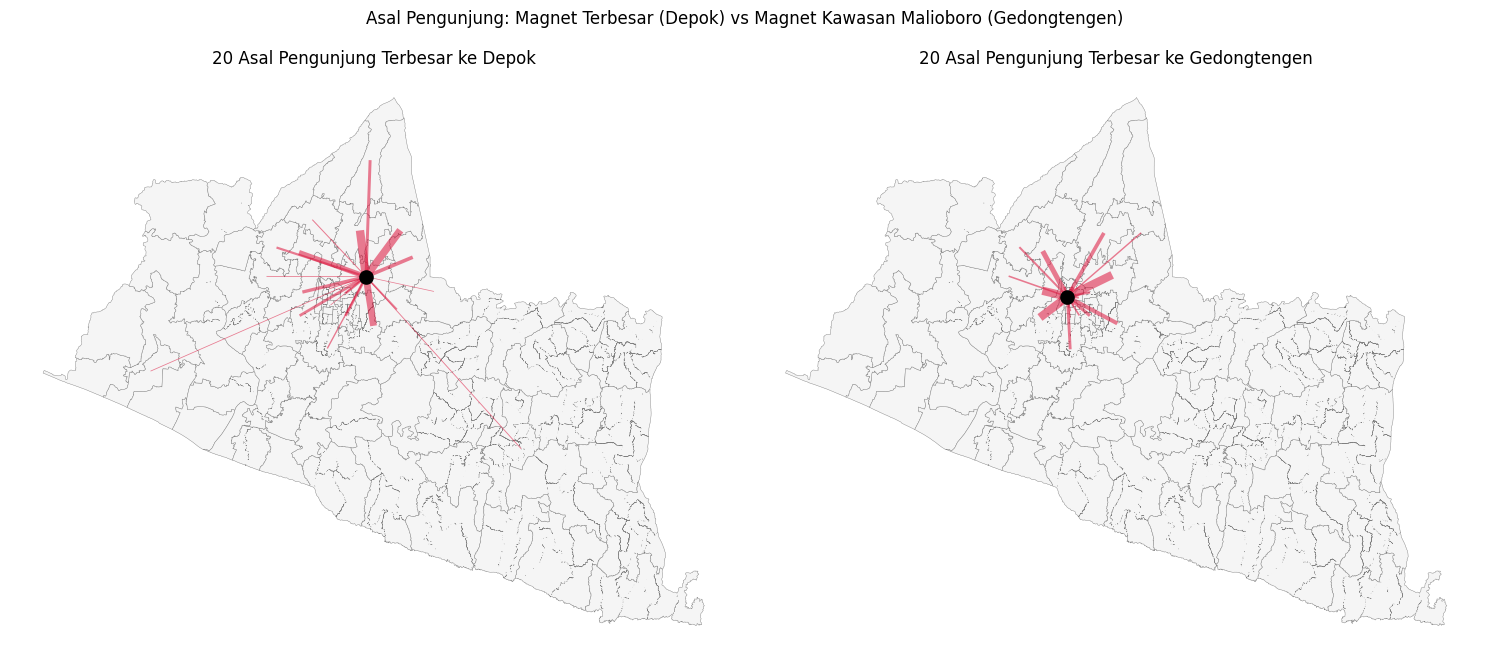

In [87]:
# 7.8 Peta aliran dari 20 kapanewon asal terbesar
def peta_aliran(kode_tujuan, ax, n=20):
    aliran = (data[data["dest_code"] == kode_tujuan]
              .groupby("origin_code")["n_maids"].sum() / JUMLAH_BULAN).nlargest(n)

    peta.plot(ax=ax, color="whitesmoke", edgecolor="grey", linewidth=0.3)
    x1, y1 = koordinat[kode_tujuan]
    for kode_asal, jumlah in aliran.items():
        x0, y0 = koordinat[kode_asal]
        ax.plot([x0, x1], [y0, y1], linewidth=jumlah / aliran.max() * 6, color="crimson", alpha=0.55)
    ax.scatter(x1, y1, s=90, color="black", zorder=5)

    nama = peta.loc[peta["KEC_CODE"] == kode_tujuan, "KEC_KAPN"].iat[0].title()
    ax.set_title(f"{n} Asal Pengunjung Terbesar ke {nama}")
    ax.set_axis_off()

fig, axes = plt.subplots(1, 2, figsize=(15, 7))
peta_aliran("34.04.07", axes[0])   # Depok
peta_aliran("34.71.05", axes[1])   # Gedongtengen
plt.suptitle("Asal Pengunjung: Magnet Terbesar (Depok) vs Magnet Kawasan Malioboro (Gedongtengen)")
plt.tight_layout()
plt.show()

Depok menarik pengunjung dari wilayah yang luas di Sleman dan Bantul, sedangkan pengunjung Gedongtengen datang dari kapanewon di sekitar pusat kota.

In [88]:
# 7.9 Diagram Sankey: aliran dari kabupaten/kota asal ke 6 kapanewon magnet terbesar
import plotly.graph_objects as go

TOP_SANKEY = magnet_absolut.head(6)["dest_code"].tolist()
aliran_sankey = (data[data["dest_code"].isin(TOP_SANKEY)]
                 .groupby(["origin_kab_kota", "dest_kapanewon"], as_index=False)["n_maids"].sum())
aliran_sankey["rata2_hp_per_bulan"] = aliran_sankey["n_maids"] / JUMLAH_BULAN

# Setiap kotak (node) di diagram perlu nomor urut
label_asal = ["Kab. " + k.title() for k in sorted(aliran_sankey["origin_kab_kota"].unique())]
label_tujuan = [t.title() for t in aliran_sankey["dest_kapanewon"].unique()]
semua_label = label_asal + label_tujuan
nomor_label = {nama: i for i, nama in enumerate(semua_label)}

fig = go.Figure(go.Sankey(
    node=dict(label=semua_label, pad=15),
    link=dict(source=[nomor_label["Kab. " + k.title()] for k in aliran_sankey["origin_kab_kota"]],
              target=[nomor_label[t.title()] for t in aliran_sankey["dest_kapanewon"]],
              value=aliran_sankey["rata2_hp_per_bulan"])))
fig.update_layout(title="Aliran Pengunjung dari Kabupaten/Kota ke 6 Kapanewon Magnet Terbesar "
                        "(rata-rata HP per bulan, Des 2021 – Feb 2022)", height=550)
fig.show()

Sleman menjadi penyumbang pengunjung terbesar ke enam magnet teratas.

### Catatan: rasio keramaian siang/malam

Rasio keramaian siang/malam tidak sejalan dengan skor magnet (Spearman 0,19 dan −0,10), karena data per jam lebih mencerminkan pola pemakaian HP daripada perpindahan orang. Rasio ini tidak dipakai.

In [89]:
# Bukti untuk catatan: rasio keramaian siang/malam dibandingkan dengan skor magnet
BULAN_ANALISIS = ["2021-12", "2022-01", "2022-02"]
per_jam = pres[pres["date"].str[:7].isin(BULAN_ANALISIS)].copy()
per_jam["waktu"] = np.select([per_jam["hour"].between(8, 17), per_jam["hour"].between(0, 5)],
                             ["siang", "malam"], default="lainnya")
per_jam = per_jam[per_jam["waktu"] != "lainnya"]

siang_malam = per_jam.pivot_table(index=["kapanewon_code", "kapanewon", "kab_kota"],
                                  columns="waktu", values="n_maids", aggfunc="mean").reset_index()
siang_malam["rasio_siang_malam"] = siang_malam["siang"] / siang_malam["malam"]

# Persentase jam malam yang datanya tersedia (tidak disensor)
jumlah_jam_malam = per_jam["date"].nunique() * 6
jam_malam_terisi = per_jam[per_jam["waktu"] == "malam"].groupby("kapanewon_code").size()
siang_malam["cakupan_malam"] = siang_malam["kapanewon_code"].map(jam_malam_terisi / jumlah_jam_malam)

banding = (siang_malam
           .merge(magnet_absolut[["dest_code", "perkiraan_orang"]],
                  left_on="kapanewon_code", right_on="dest_code", how="left")
           .merge(magnet[["dest_code", "indeks_magnet"]], on="dest_code", how="left"))
print("Spearman rasio siang/malam vs magnet absolut:",
      round(banding["rasio_siang_malam"].corr(banding["perkiraan_orang"], method="spearman"), 2))
print("Spearman rasio siang/malam vs indeks magnet :",
      round(banding["rasio_siang_malam"].corr(banding["indeks_magnet"], method="spearman"), 2))
display(siang_malam.sort_values("rasio_siang_malam", ascending=False).head(8).round(2))

Spearman rasio siang/malam vs magnet absolut: 0.19
Spearman rasio siang/malam vs indeks magnet : -0.1


waktu,kapanewon_code,kapanewon,kab_kota,malam,siang,rasio_siang_malam,cakupan_malam
31,34.03.03,PLAYEN,GUNUNGKIDUL,18.25,65.65,3.60,0.94
10,34.01.11,SAMIGALUH,KULON PROGO,15.32,51.88,3.39,0.89
29,34.03.01,WONOSARI,GUNUNGKIDUL,52.32,172.91,3.30,0.99
9,34.01.10,NANGGULAN,KULON PROGO,19.89,64.62,3.25,0.97
7,34.01.08,KOKAP,KULON PROGO,24.03,77.98,3.25,0.98
17,34.02.06,PANDAK,BANTUL,35.75,114.71,3.21,1.00
5,34.01.06,SENTOLO,KULON PROGO,24.83,78.48,3.16,0.99
55,34.04.09,PRAMBANAN,SLEMAN,30.37,95.18,3.13,0.99


## 8. Kesimpulan dan Keterbatasan

### Ringkasan per tahap
- **EDA:** Distribusi aliran sangat miring ke kanan, jumlah HP turun tajam pada Maret–April 2022, dan dua kapanewon bernama JETIS membuat hitungan berbasis nama keliru (77, seharusnya 78).
- **Data Cleaning:** Data dibatasi pada Des 2021 – Feb 2022 dan aliran ke kapanewon sendiri dibuang (9.894 → 7.638 baris). Sensor privasi menghapus 48,6% pasangan asal–tujuan, tetapi 95,3% total aliran tetap tersimpan.
- **Data Integration:** Data aliran, jumlah HP berumah, dan penduduk digabung menggunakan kode kapanewon. Jumlah HP berumah berkorelasi kuat dengan penduduk (r = 0,83; 0,85 tanpa Gondomanan), sehingga sampel cukup mewakili sebaran penduduk.
- **Transformation:** Aliran dinormalisasi menjadi rate dan indeks magnet, lalu didiskretisasi dengan batas indeks = 1.
- **Data Warehouse:** Data disusun sebagai star schema dengan dua tabel fakta (fact constellation). Roll-up menunjukkan aliran antar kabupaten terbesar adalah Sleman → Kota Yogyakarta.

### Kesimpulan
1. **Magnet relatif terpusat di Kota Yogyakarta.** Kawasan Malioboro dan sekitarnya menarik pengunjung jauh melebihi jumlah warganya.
2. **Magnet absolut berada di kapanewon penyangga kota**, terutama Depok, Banguntapan, Kasihan, Gamping, dan Ngaglik.
3. **Pengunjung umumnya berasal dari kapanewon tetangga**, dan Sleman menjadi penyumbang pengunjung terbesar.
4. **Kapanewon pinggiran**, terutama di timur Gunungkidul, cenderung menjadi pengirim.

### Keterbatasan
- Satu HP tidak sama dengan satu orang, dan sampel bukan sampel acak penduduk.
- Analisis hanya mencakup tiga bulan, termasuk libur Natal dan Tahun Baru.
- Indeks magnet dapat sangat tinggi di kapanewon dengan sedikit warga (misalnya Ngampilan).
- Perkiraan jumlah orang dapat membesar di kapanewon asal dengan sampel kecil.
- Roll-up antar kabupaten menghitung kunjungan, bukan HP unik.
- Sumber peta batas kapanewon belum dikonfirmasi.

### Privasi
Dataset hanya berisi data agregat dengan k-anonymity (k = 5): baris dengan kurang dari 5 HP dihapus dan tidak ada data per individu. Baris yang tidak ada diperlakukan sebagai "kurang dari 5 HP", bukan nol, dan tidak ada upaya merekonstruksi data yang disensor.